# Leicester 2015/16: where their players led the league

Follow-up to `02_leicester_title.ipynb`. This notebook:

1. Compares **distance covered** by team (external data, because event data has no running distances)
2. Builds **32 player metrics** for every outfield player and finds where Leicester players ranked in the league's top 3
3. Looks closer at **Vardy's xG**, **Mahrez's dribbling** and **Kanté's** ball-winning

**Rankings:** season totals compare all outfield players. Per-90 rankings only include players with 900+ minutes (327 players).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mplsoccer import Pitch, VerticalPitch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "2_27"
FIGS = ROOT / "reports" / "figures"

events = pd.read_parquet(DATA / "events.parquet").sort_values(["match_id", "index"])
players = pd.read_parquet(DATA / "player_season.parquet").set_index("player_id")
LEI = "Leicester City"

BLUE, GREY, DARK, MUTED = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
SOURCE = "Data: StatsBomb Open Data, Premier League 2015/16"

def subtitle(ax, text):
    ax.annotate(text, xy=(0, 1.01), xycoords="axes fraction", fontsize=9.5, color=MUTED)

def source(fig, text=SOURCE):
    fig.text(0.01, -0.02, text, fontsize=8, color="#8A8880")

## 1. Distance covered

StatsBomb event data records on-ball actions only, with no player tracking, so running distance can't be computed from it.
The figures below were published by Sky Sports from the **EA Sports Player Performance Index**, the league's official rating system at the time ([Sky Sports, 8 March 2016](https://www.skysports.com/football/news/10196163/tireless-tottenham-running-further-in-2016-than-any-other-premier-league-team)).

**Caveat:** they cover the season only up to 8 March 2016 (about 29 matches), and Sky listed only the 10 teams that ran furthest. Teams outside this list, including Manchester City, Liverpool and Chelsea, ran less than 109.8 km per 90 minutes.

In [2]:
distance = pd.DataFrame([
    ("AFC Bournemouth", 3398.9, 117.2), ("Tottenham Hotspur", 3360.5, 115.9),
    ("West Bromwich Albion", 3254.2, 112.2), ("Manchester United", 3229.3, 111.4),
    ("West Ham United", 3215.3, 110.9), ("Leicester City", 3202.9, 110.4),
    ("Arsenal", 3199.6, 110.3), ("Crystal Palace", 3191.7, 110.1),
    ("Sunderland", 3184.5, 109.8), ("Southampton", 3184.0, 109.8),
], columns=["team", "km_total_to_8_march", "km_per_90"])
distance

,team,km_total_to_8_march,km_per_90
0,AFC Bournemouth,3398.9,117.2
1,Tottenham Hotspur,3360.5,115.9
2,West Bromwich Albion,3254.2,112.2
3,Manchester United,3229.3,111.4
4,West Ham United,3215.3,110.9
5,Leicester City,3202.9,110.4
6,Arsenal,3199.6,110.3
7,Crystal Palace,3191.7,110.1
8,Sunderland,3184.5,109.8
9,Southampton,3184.0,109.8


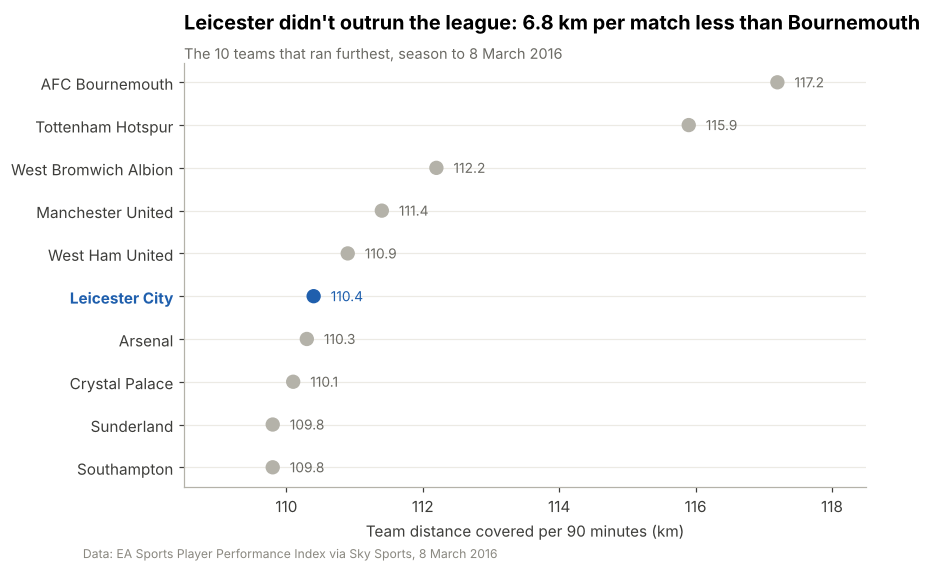

In [3]:
d = distance.sort_values("km_per_90")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d.km_per_90, d.team, s=70, color=[BLUE if t == LEI else GREY for t in d.team], zorder=3)
for i, (t, v) in enumerate(zip(d.team, d.km_per_90)):
    ax.annotate(f"{v:.1f}", (v + 0.25, i), va="center", fontsize=9, color=BLUE if t == LEI else MUTED)
for lbl in ax.get_yticklabels():
    if lbl.get_text() == LEI:
        lbl.set_color(BLUE); lbl.set_fontweight("bold")
ax.set_xlim(108.5, 118.5)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Team distance covered per 90 minutes (km)")
gap = distance.km_per_90.max() - distance.set_index("team").km_per_90[LEI]
ax.set_title(f"Leicester didn't outrun the league: {gap:.1f} km per match less than Bournemouth", pad=22)
subtitle(ax, "The 10 teams that ran furthest, season to 8 March 2016")
source(fig, "Data: EA Sports Player Performance Index via Sky Sports, 8 March 2016")
fig.savefig(FIGS / "06_distance_covered.png"); plt.show()

## 2. Player metrics

Definitions (StatsBomb pitch is 120 × 80 yards, attacking left to right):

- **Progressive pass / carry:** moves the ball at least 10 yards towards goal (passes must end in the opponent's 2/3 of the pitch)
- **Box:** x ≥ 102 and 18 ≤ y ≤ 62. "Into the box" means starting outside it and ending inside it.
- **xA (expected assists):** xG of the shot that a key pass led to
- **Big chance:** a non-penalty shot worth at least 0.3 xG
- **Dribble success %:** only for players with 30+ attempts

In [4]:
f = lambda mask: events[mask].groupby("player_id").size()
box = lambda x, y: (x >= 102) & (y >= 18) & (y <= 62)

shots = events[events.type == "Shot"].assign(xg=lambda d: d.shot_statsbomb_xg.astype(float),
                                              goal=lambda d: d.shot_outcome == "Goal")
np_shots = shots[shots.shot_type != "Penalty"]

key = events[events.pass_shot_assist | events.pass_goal_assist][["match_id", "possession", "index", "player_id"]]
nxt = shots[["match_id", "possession", "index", "xg"]].rename(columns={"index": "shot_index"})
xa = (key.merge(nxt, on=["match_id", "possession"]).query("shot_index > index")
         .sort_values("shot_index").drop_duplicates(["match_id", "index"]).groupby("player_id").xg.sum())

P = events[events.type == "Pass"]
done = P.pass_outcome.isna()
open_play = ~P.pass_type.isin(["Corner", "Throw-in", "Kick Off", "Free Kick", "Goal Kick"])
C = events[events.type == "Carry"]
D = events[events.type == "Dribble"]
T = events[(events.type == "Duel") & (events.duel_type == "Tackle")]
Pr = events[events.type == "Pressure"]
g = lambda df: df.groupby("player_id").size()

metrics = {
    "Goals": shots.groupby("player_id").goal.sum(),
    "Non-penalty goals": np_shots.groupby("player_id").goal.sum(),
    "xG": shots.groupby("player_id").xg.sum(),
    "Non-penalty xG": np_shots.groupby("player_id").xg.sum(),
    "Non-penalty goals minus xG": np_shots.groupby("player_id").goal.sum() - np_shots.groupby("player_id").xg.sum(),
    "Shots": g(shots),
    "Shots on target": g(shots[shots.shot_outcome.isin(["Goal", "Saved", "Saved To Post"])]),
    "Big chances": g(np_shots[np_shots.xg >= 0.3]),
    "Counter-attack goals": g(shots[shots.goal & (shots.play_pattern == "From Counter")]),
    "Assists": f(events.pass_goal_assist),
    "Chances created": f(events.pass_shot_assist | events.pass_goal_assist),
    "Expected assists (xA)": xa,
    "Through balls completed": g(P[done & P.pass_through_ball]),
    "Progressive passes": g(P[done & open_play & ((P.pass_end_x - P.start_x) >= 10) & (P.pass_end_x >= 40)]),
    "Passes into the box": g(P[done & open_play & box(P.pass_end_x, P.pass_end_y) & ~box(P.start_x, P.start_y)]),
    "Crosses completed": g(P[done & P.pass_cross]),
    "Long passes completed": g(P[done & (P.pass_length.astype(float) >= 32)]),
    "Dribbles completed": g(D[D.dribble_outcome == "Complete"]),
    "Dribbles attempted": g(D),
    "Progressive carries": g(C[(C.carry_end_x - C.start_x) >= 10]),
    "Carries into the box": g(C[box(C.carry_end_x, C.carry_end_y) & ~box(C.start_x, C.start_y)]),
    "Fouls won": f(events.type == "Foul Won"),
    "Tackles": g(T),
    "Tackles won": g(T[T.duel_outcome.isin(["Won", "Success In Play", "Success Out"])]),
    "Interceptions": f(events.type == "Interception"),
    "Tackles + interceptions": g(T).add(f(events.type == "Interception"), fill_value=0),
    "Ball recoveries": f(events.type == "Ball Recovery"),
    "Pressures": g(Pr),
    "Pressures in attacking third": g(Pr[Pr.start_x >= 80]),
    "Blocks": f(events.type == "Block"),
    "Clearances": f(events.type == "Clearance"),
}
stats = players.join(pd.DataFrame(metrics)).fillna(0)
stats["Dribble success %"] = np.where(stats["Dribbles attempted"] >= 30,
                                      stats["Dribbles completed"] / stats["Dribbles attempted"].replace(0, np.nan) * 100, np.nan)
outfield = stats[stats.position_group != "Goalkeeper"]
print(f"{len(metrics) + 1} metrics for {len(outfield)} outfield players")

32 metrics for 503 outfield players


## 3. Where Leicester players ranked in the league's top 3

For each metric, the table shows the Leicester player's rank and value, the league leader, and the best player from another club.

In [5]:
rows = []
for metric in list(metrics) + ["Dribble success %"]:
    bases = [("Season total", outfield[metric])]
    if metric != "Dribble success %":
        reg = outfield[outfield.minutes >= 900]
        bases.append(("Per 90", reg[metric] / reg.minutes * 90))
    for basis, values in bases:
        ranked = values.dropna().sort_values(ascending=False)
        team = outfield.loc[ranked.index, "main_team"]
        best_other = ranked[team != LEI]
        for rank, (pid, v) in enumerate(ranked.head(3).items(), start=1):
            if team[pid] == LEI:
                rows.append({
                    "Metric": metric, "Basis": basis, "Rank": rank,
                    "Leicester player": outfield.loc[pid, "display_name"], "Value": round(v, 2),
                    "Best from another club": f"{outfield.loc[best_other.index[0], 'display_name']} ({best_other.iloc[0]:.2f})",
                    "_other": best_other.iloc[0],
                })
leaders = pd.DataFrame(rows).sort_values(["Rank", "Leicester player", "Basis"]).reset_index(drop=True)
leaders.drop(columns="_other")

,Metric,Basis,Rank,Leicester player,Value,Best from another club
0,Blocks,Per 90,1,Christian Fuchs,3.64,DeAndre Yedlin (3.50)
1,Blocks,Season total,1,Christian Fuchs,115.00,Craig Dawson (105.00)
2,xG,Season total,1,Jamie Vardy,22.30,Harry Kane (21.64)
3,Counter-attack goals,Season total,1,Jamie Vardy,5.00,Sadio Mané (4.00)
4,Pressures in attacking third,Season total,1,Jamie Vardy,271.00,Salomón Rondón (258.00)
5,Tackles,Per 90,1,N'Golo Kanté,4.64,Valon Behrami (4.32)
6,Tackles + interceptions,Per 90,1,N'Golo Kanté,7.76,Jan Kirchhoff (6.93)
7,Ball recoveries,Per 90,1,N'Golo Kanté,8.49,Idrissa Gueye (8.29)
8,Tackles,Season total,1,N'Golo Kanté,164.00,Idrissa Gueye (153.00)
9,Tackles won,Season total,1,N'Golo Kanté,102.00,Idrissa Gueye (100.00)


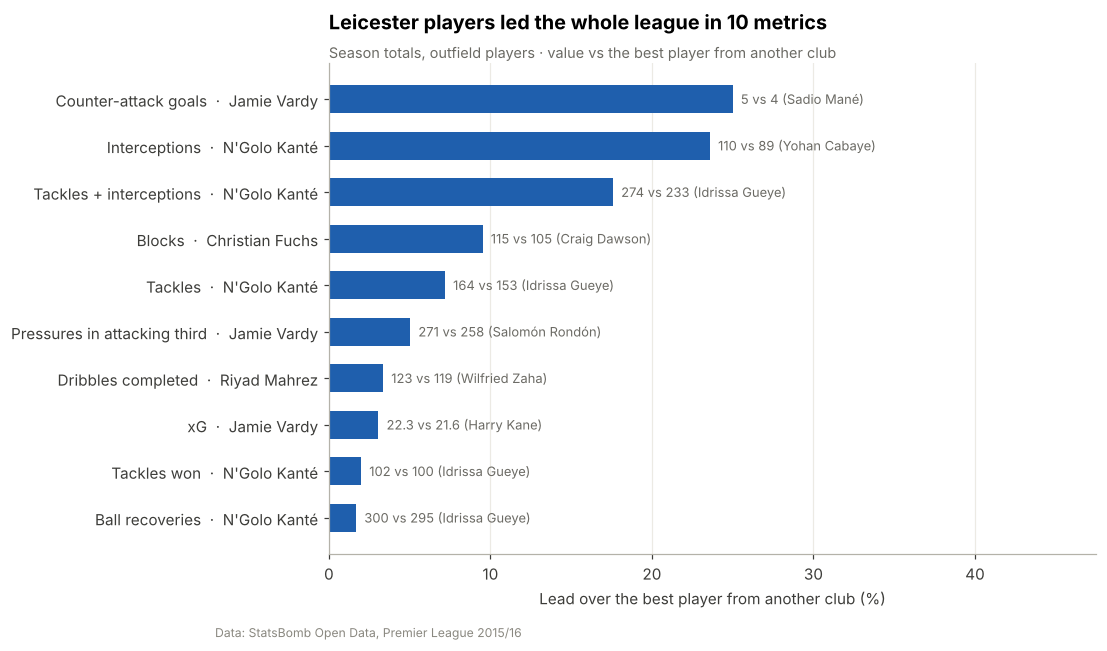

In [6]:
firsts = leaders[(leaders.Rank == 1) & (leaders.Basis == "Season total")
                 & (leaders.Metric != "Dribbles attempted")].copy()
firsts["margin_pct"] = (firsts.Value / firsts._other - 1) * 100
firsts = firsts.sort_values("margin_pct")

fig, ax = plt.subplots(figsize=(9, 5.8))
y = np.arange(len(firsts))
ax.barh(y, firsts.margin_pct, color=BLUE, height=0.6)
labels = [f"{m}  ·  {p}" for m, p in zip(firsts.Metric, firsts["Leicester player"])]
ax.set_yticks(y, labels)
for i, (_, r) in enumerate(firsts.iterrows()):
    digits = 1 if r["Value"] % 1 else 0
    other_name = r["Best from another club"].rsplit(" (", 1)[0]
    ax.annotate(f"{r['Value']:.{digits}f} vs {r['_other']:.{digits}f} ({other_name})", (r["margin_pct"] + 0.5, i),
                va="center", fontsize=8.5, color=MUTED)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, firsts.margin_pct.max() * 1.9)
ax.set_xlabel("Lead over the best player from another club (%)")
ax.set_title(f"Leicester players led the whole league in {len(firsts)} metrics", pad=22)
subtitle(ax, "Season totals, outfield players · value vs the best player from another club")
source(fig); fig.savefig(FIGS / "07_leicester_league_leaders.png"); plt.show()

## 4. Jamie Vardy: shot locations and xG

In [7]:
vardy_id = stats.index[stats.display_name == "Jamie Vardy"][0]
v = shots[shots.player_id == vardy_id]
v_np = v[v.shot_type != "Penalty"]
print(f"Shots {len(v)}, goals {v.goal.sum()} ({(v.shot_type == 'Penalty').sum()} penalties, "
      f"{v[v.shot_type == 'Penalty'].goal.sum()} scored)")
print(f"xG {v.xg.sum():.1f} (most in the league), non-penalty xG {v_np.xg.sum():.1f}, non-penalty goals {v_np.goal.sum()}")
print(f"xG per non-penalty shot {v_np.xg.mean():.3f}; league average for forwards "
      f"{np_shots[np_shots.player_id.isin(outfield[outfield.position_group == 'Forward'].index)].xg.mean():.3f}")
print("Goals by play pattern:", v[v.goal].play_pattern.value_counts().to_dict())

Shots 118, goals 24 (6 penalties, 5 scored)
xG 22.3 (most in the league), non-penalty xG 17.6, non-penalty goals 19
xG per non-penalty shot 0.157; league average for forwards 0.111
Goals by play pattern: {'Regular Play': 8, 'Other': 5, 'From Counter': 5, 'From Free Kick': 2, 'From Throw In': 2, 'From Goal Kick': 1, 'From Keeper': 1}


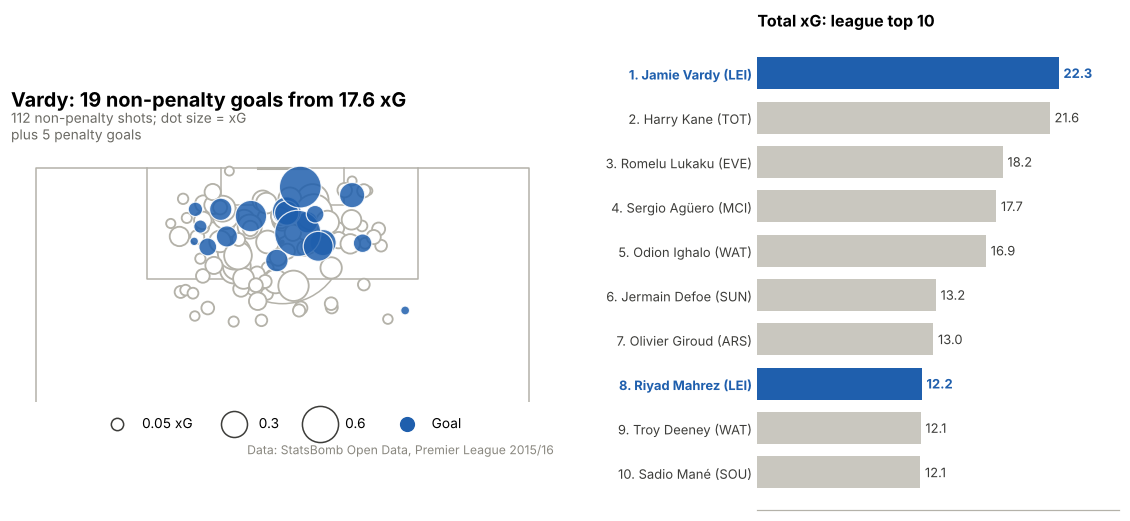

In [8]:
import sys; sys.path.insert(0, str(ROOT / "src"))
from football_analytics.viz import leaderboard
fig = plt.figure(figsize=(13, 5.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.5, 1], wspace=0.45)
ax, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
pitch = VerticalPitch(pitch_type="statsbomb", half=True, line_color=GREY, linewidth=1, pad_bottom=-22)
pitch.draw(ax=ax)
leaderboard(ax2, outfield["xG"], outfield.display_name, outfield.main_team, fmt="{:.1f}",
            title="Total xG: league top 10")
miss, goal = v_np[~v_np.goal], v_np[v_np.goal]
pitch.scatter(miss.start_x, miss.start_y, s=miss.xg * 900 + 20, ax=ax, facecolor="white", edgecolor=GREY, lw=1.2, zorder=2)
pitch.scatter(goal.start_x, goal.start_y, s=goal.xg * 900 + 20, ax=ax, color=BLUE, alpha=0.85, edgecolor="white", lw=0.8, zorder=3)
for size, lab in [(0.05, "0.05 xG"), (0.3, "0.3"), (0.6, "0.6")]:
    ax.scatter([], [], s=size * 900 + 20, facecolor="white", edgecolor=DARK, label=lab)
ax.scatter([], [], s=80, color=BLUE, label="Goal")
ax.legend(loc="upper center", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0.0), labelspacing=1.4)
ax.set_title(f"Vardy: {v_np.goal.sum()} non-penalty goals from {v_np.xg.sum():.1f} xG", loc="left",
             fontsize=13, fontweight="bold", pad=24)
ax.annotate(f"{len(v_np)} non-penalty shots; dot size = xG\nplus {v[v.shot_type == 'Penalty'].goal.sum()} penalty goals", xy=(0, 1.015), xycoords="axes fraction", fontsize=9, color=MUTED)
ax.annotate(SOURCE, xy=(1, -0.2), xycoords="axes fraction", ha="right", fontsize=8, color="#8A8880")
fig.savefig(FIGS / "08_vardy_shot_map.png"); plt.show()

## 5. Riyad Mahrez: dribbling

In [9]:
mahrez_id = stats.index[stats.display_name == "Riyad Mahrez"][0]
mz = events[(events.player_id == mahrez_id) & (events.type == "Dribble")]
ok = mz[mz.dribble_outcome == "Complete"]
attempts = outfield["Dribbles attempted"]
q = outfield[attempts >= 100].assign(success=lambda d: d["Dribbles completed"] / d["Dribbles attempted"] * 100)
print(f"Mahrez: {len(ok)} completed of {len(mz)} ({len(ok) / len(mz):.0%}); "
      f"{(ok.start_x >= 80).mean():.0%} of completed dribbles in the attacking third")
q.sort_values("Dribbles completed", ascending=False)[["display_name", "main_team", "Dribbles completed",
                                                       "Dribbles attempted", "success"]].head(6).round(1)

Mahrez: 123 completed of 218 (56%); 55% of completed dribbles in the attacking third


,display_name,main_team,Dribbles completed,Dribbles attempted,success
player_id,,,,,
3814,Riyad Mahrez,Leicester City,123.0,218.0,56.4
3507,Wilfried Zaha,Crystal Palace,119.0,198.0,60.1
3385,Alexis Sánchez,Arsenal,103.0,165.0,62.4
4275,Ross Barkley,Everton,94.0,145.0,64.8
3450,Jordan Ayew,Aston Villa,85.0,158.0,53.8
3037,Mousa Dembélé,Tottenham Hotspur,81.0,101.0,80.2


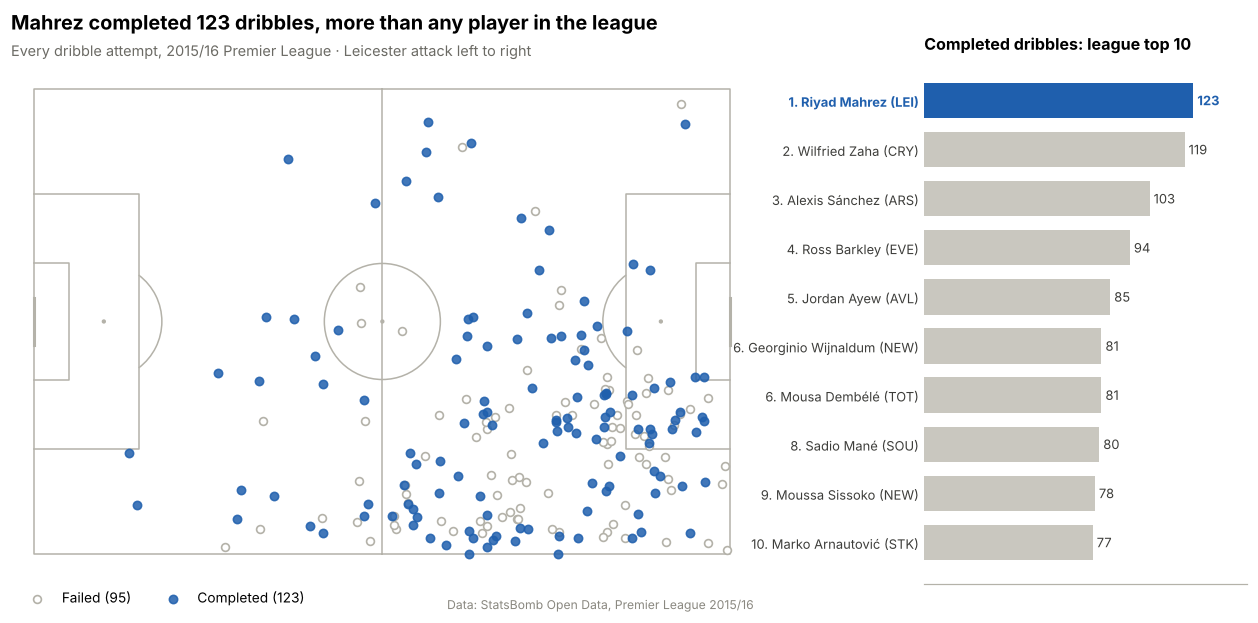

In [10]:
import sys; sys.path.insert(0, str(ROOT / "src"))
from football_analytics.viz import leaderboard
fig = plt.figure(figsize=(14.5, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[2.3, 1], wspace=0.32)
ax, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
pitch = Pitch(pitch_type="statsbomb", line_color=GREY, linewidth=1)
pitch.draw(ax=ax)
leaderboard(ax2, outfield["Dribbles completed"], outfield.display_name, outfield.main_team,
            title="Completed dribbles: league top 10")
fail = mz[mz.dribble_outcome != "Complete"]
pitch.scatter(fail.start_x, fail.start_y, ax=ax, s=26, facecolor="white", edgecolor=GREY, lw=1.1, label=f"Failed ({len(fail)})")
pitch.scatter(ok.start_x, ok.start_y, ax=ax, s=30, color=BLUE, alpha=0.85, label=f"Completed ({len(ok)})")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.0), ncol=2, frameon=False, fontsize=9)
ax.set_title(f"Mahrez completed {len(ok)} dribbles, more than any player in the league",
             loc="left", fontsize=13, fontweight="bold", pad=24)
ax.annotate("Every dribble attempt, 2015/16 Premier League · Leicester attack left to right",
            xy=(0, 1.02), xycoords="axes fraction", fontsize=9.5, color=MUTED)
ax.annotate(SOURCE, xy=(1, -0.04), xycoords="axes fraction", ha="right", va="top", fontsize=8, color="#8A8880")
fig.savefig(FIGS / "09_mahrez_dribbles.png"); plt.show()

## 6. Leicester as a team: where they ranked

The same metrics summed by team (all 20 teams; 1 = highest).

In [11]:
team_totals = stats.groupby("main_team")[list(metrics)].sum()
team_rank = team_totals.rank(ascending=False, method="min").astype(int)
team_view = pd.DataFrame({"Leicester": team_totals.loc[LEI].round(1), "Rank (of 20)": team_rank.loc[LEI],
                          "League leader": team_totals.idxmax(), "Leader value": team_totals.max().round(1)})
team_view.sort_values("Rank (of 20)").head(15)

,Leicester,Rank (of 20),League leader,Leader value
xG,66.3,1,Leicester City,66.3
Blocks,961.0,1,Leicester City,961.0
Tackles + interceptions,1364.0,1,Leicester City,1364.0
Interceptions,497.0,2,Manchester City,499.0
Clearances,1247.0,2,West Bromwich Albion,1265.0
Goals,67.0,3,Manchester City,71.0
Counter-attack goals,6.0,3,Manchester City,9.0
Tackles,867.0,3,Liverpool,877.0
Tackles won,528.0,3,Liverpool,533.0
Pressures in attacking third,1244.0,3,AFC Bournemouth,1351.0


## Summary

- **Distance:** Leicester ran **110.4 km per 90 minutes**, about the same as Arsenal and 6.8 km less than Bournemouth (EA Sports PPI, season to 8 March 2016). They didn't win by outrunning teams.
- **Vardy:** the most xG in the league (22.3, including 6 penalties) and the most counter-attack goals (5). His chances were unusually good: 0.157 xG per non-penalty shot, against 0.111 for forwards in general. He also made the most pressures in the attacking third of any player (271), so the striker was the first line of the press.
- **Mahrez:** the most completed dribbles in the league (123 of 218, 56%). He beat his xG by +5.5 non-penalty goals, 2nd only to Agüero, and won the 2nd-most fouls.
- **Kanté:** 1st in tackles, tackles won, interceptions, tackles plus interceptions and ball recoveries. Also 2nd in pressures and blocks.
- **Fuchs:** the most blocks in the league (115), just ahead of Kanté (114). Huth made the 2nd-most clearances.

- **As a team:** Leicester ranked 1st of 20 in total xG (66.3), blocks (961), and tackles plus interceptions (1,364).

Leicester players led on effort and ball-winning metrics (pressing, tackles, interceptions, blocks) and on directness metrics (counter goals, dribbles). They didn't lead on possession metrics such as progressive passes.